# 阶段2补充：写报告时的回头检验

**背景：** 阶段2 的结论（`docs/stage_summaries/stage_2.md`）在写成分析报告时，需要对每一个准备写进报告的说法追问一句：现有证据足以支撑它吗？这本 notebook 记录了这个过程。每一节都从前面模块里已有的一个事实出发，先看全貌，发现不对劲的地方后再聚焦检验。

| 节 | 触发的问题 | 来自 |
| --- | --- | --- |
| 1 | 杠杆按"可减少的差评数"排序，但北极星指标是 GMV。差评会影响 GMV 吗？ | D-034、`s2_impact_sizing` |
| 2 | 买家数在 2018 年不再增长，但一直有新卖家签约。新卖家带来了多少 GMV？ | 模块1、模块7 |
| 3 | 延误评价有 74% 写于收货前，而差评率恰好在延误第 4 天跳升。两者有关吗？ | 模块3 3.2、3.5 |
| 4 | 3 个延误率最高的月份真的是订单高峰吗？延误为什么集中在这几个月？ | 模块3 3.6、D-032 |
| 5 | 多件订单差评率高的原因"无法确认"。评论文本能回答吗？ | 模块3 3.7 |
| 6 | 卖家分层对 575 个卖家逐一检验，会有多少误判？"问题卖家多在家居类"的解释成立吗？渠道比较是否也受影响？ | 模块6 6.2、模块7 |

**数据：** `dws_order_fulfillment`、`dwd_orders`、`dwd_order_items`、`dwd_order_reviews`、`dwd_products`、`dws_seller`、`ads_m6_seller_tier`

**原则：** 不修改前面模块的结论；检验结果在这里记录，对应模块的结论处加"后续检验见本 notebook"的指针，新的口径决策记入决策日志（D-035 起）。

In [1]:
from olist_utils import run_query, set_style, COLORS
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

set_style()

## 1. 差评会影响 GMV 吗？

`s2_impact_sizing` 把各项建议统一换算成"可减少的差评数"（D-034），D-034 同时写明"缺少差评与收入之间关系的数据"。但项目的主问题是在保持交易规模增长的同时提升满意度，北极星指标是 GMV。如果差评对 GMV 没有影响，那么按差评排序的杠杆就只回答了一半的问题。

Olist 的买家通常不会回到同一个平台复购（模块5），所以差评影响 GMV 的途径更可能在卖家一侧：差评拉低卖家在各电商平台上的评分，进而影响它之后的销量。下面检验：**一个卖家差评变多之后，它之后的 GMV 会不会变少？**

### 1.1 先做一个简单比较

按卖家在 2017 年 9~12 月的差评率分成三组，比较它们在 2018 年 1~4 月的 GMV 变化。只用单卖家订单（D-029），且这 4 个月至少有 20 条评价，避免差评率被极少数订单左右。

In [2]:
sql_seller_window = '''
SELECT seller_id,
       SUM(CASE WHEN purchase_month BETWEEN '2017-09' AND '2017-12' THEN has_review    ELSE 0 END) AS n_rev,
       SUM(CASE WHEN purchase_month BETWEEN '2017-09' AND '2017-12' THEN is_bad_review ELSE 0 END) AS n_bad,
       SUM(CASE WHEN purchase_month BETWEEN '2017-09' AND '2017-12' THEN order_gmv     ELSE 0 END) AS gmv_before,
       SUM(CASE WHEN purchase_month BETWEEN '2018-01' AND '2018-04' THEN order_gmv     ELSE 0 END) AS gmv_after
FROM dws_order_fulfillment
WHERE seller_id IS NOT NULL
GROUP BY seller_id
'''
sw = run_query(sql_seller_window).astype({"n_rev": float, "n_bad": float, "gmv_before": float, "gmv_after": float})
sw = sw[sw["n_rev"] >= 20].copy()
sw["bad_rate"] = sw["n_bad"] / sw["n_rev"]
sw["growth"] = sw["gmv_after"] / sw["gmv_before"]
sw["group"] = pd.qcut(sw["bad_rate"], 3, labels=["差评率低", "差评率中", "差评率高"])

summary = sw.groupby("group", observed=True).agg(
    sellers=("seller_id", "size"),
    bad_rate=("bad_rate", "mean"),
    median_growth=("growth", "median"),
    gmv_before=("gmv_before", "sum"),
    gmv_after=("gmv_after", "sum"),
)
summary["total_growth"] = summary["gmv_after"] / summary["gmv_before"]
summary.round(3)

,sellers,bad_rate,median_growth,gmv_before,gmv_after,total_growth
group,,,,,,
差评率低,80,0.045,0.969,625488.31,470088.35,0.752
差评率中,80,0.113,0.853,695462.28,705778.58,1.015
差评率高,80,0.214,0.752,663273.50,595302.75,0.898


**观察：** 按中位数看，差评率越高的组，之后的 GMV 增长越低（约 0.97 → 0.85 → 0.75）；但按合计 GMV 看并不单调，差评率中等的组反而最好。每组只有 80 个卖家，少数大卖家就能左右合计值。

更根本的问题是**不同卖家之间不可比**：差评率高的卖家可能卖的是不同品类、处在不同的成长阶段，GMV 的差异不一定来自差评。要排除这些差异，应该比较**同一个卖家**在差评多的月份和差评少的月份之后的表现（与模块6 6.3 卖家内部对比的思路相同）。

### 1.2 同一卖家的逐月对比

把数据整理成"卖家 × 月份"，检验：同一卖家某个月的差评率比它自己的平常水平高时，下个月的 GMV 是否比平常低。

- 控制卖家本身（卖家固定效应）：每个卖家只和自己比
- 控制月份（月份固定效应）：排除大促、季节等全平台共同的波动
- 控制当月 GMV：当月特别忙的卖家，下个月本来就容易回落，也可能更容易出差评
- 只用当月至少 5 条评价的卖家月份；置信区间按卖家做 Bootstrap（同一卖家的各月份一起抽样）

In [3]:
sql_panel = '''
SELECT seller_id, purchase_month,
       SUM(has_review)    AS n_rev,
       SUM(is_bad_review) AS n_bad,
       SUM(order_gmv)     AS gmv
FROM dws_order_fulfillment
WHERE seller_id IS NOT NULL
GROUP BY seller_id, purchase_month
'''
panel_all = run_query(sql_panel).astype({"n_rev": float, "n_bad": float, "gmv": float})
panel_all["month"] = pd.PeriodIndex(panel_all["purchase_month"], freq="M")

# 下个月、下两个月的 GMV（没有订单记为 0）
gmv_lookup = panel_all.set_index(["seller_id", "month"])["gmv"]
panel_all["gmv_next1"] = [gmv_lookup.get((s, m + 1), 0.0) for s, m in zip(panel_all["seller_id"], panel_all["month"])]
panel_all["gmv_next2"] = [gmv_lookup.get((s, m + 2), 0.0) for s, m in zip(panel_all["seller_id"], panel_all["month"])]
panel_all["bad_rate"] = panel_all["n_bad"] / panel_all["n_rev"]
panel_all["log_gmv"] = np.log1p(panel_all["gmv"])
panel_all["log_next1"] = np.log1p(panel_all["gmv_next1"])
panel_all["log_next2"] = np.log1p((panel_all["gmv_next1"] + panel_all["gmv_next2"]) / 2)
panel_all.shape

(15744, 12)

In [4]:
def within_slope(df, x, y, controls=("log_gmv",), n_iter=50):
    '''同时去掉卖家和月份的平均水平后（交替去均值），用最小二乘估计 x 对 y 的影响'''
    cols = [x, y, *controls]
    d = df[cols].astype(float).copy()
    for _ in range(n_iter):
        d = d - d.groupby(df["seller_id"].values).transform("mean")
        d = d - d.groupby(df["month"].values).transform("mean")
    X = d[[x, *controls]].to_numpy()
    beta = np.linalg.lstsq(X, d[y].to_numpy(), rcond=None)[0]
    return beta[0]


def bootstrap_ci(df, x, y, n_boot=200, seed=42):
    '''按卖家整体重抽样，95% 置信区间'''
    rng = np.random.default_rng(seed)
    groups = {s: g for s, g in df.groupby("seller_id")}
    ids = list(groups)
    est = []
    for _ in range(n_boot):
        draw = rng.choice(len(ids), len(ids))
        parts = [groups[ids[k]].assign(seller_id=f"{ids[k]}_{j}") for j, k in enumerate(draw)]
        est.append(within_slope(pd.concat(parts, ignore_index=True), x, y))
    return np.percentile(est, [2.5, 97.5])


# 最后两个月没有"下个月"可看，不进入分析
panel = panel_all[(panel_all["n_rev"] >= 5) & (panel_all["month"] <= pd.Period("2018-06", "M"))].reset_index(drop=True)
b = within_slope(panel, "bad_rate", "log_next1")
lo, hi = bootstrap_ci(panel, "bad_rate", "log_next1")
print(f"卖家月份 {len(panel):,} 个，卖家 {panel['seller_id'].nunique():,} 个")
print(f"差评率每高 10 个百分点，下个月 GMV 变化约 {b * 0.1:+.1%}（95% 置信区间 {lo * 0.1:+.1%} ~ {hi * 0.1:+.1%}）")

卖家月份 4,202 个，卖家 883 个
差评率每高 10 个百分点，下个月 GMV 变化约 -6.2%（95% 置信区间 -10.6% ~ -0.8%）


### 1.3 稳健性

换两个设定再估计一次：每月最少评价数 5 条 / 10 条；结果看下个月，或者下两个月的平均（看影响是否只是一次性的）。

In [5]:
rows = []
for min_rev in [5, 10]:
    d = panel_all[(panel_all["n_rev"] >= min_rev) & (panel_all["month"] <= pd.Period("2018-06", "M"))].reset_index(drop=True)
    for y, label in [("log_next1", "下个月"), ("log_next2", "下两个月平均")]:
        b_ = within_slope(d, "bad_rate", y)
        lo_, hi_ = bootstrap_ci(d, "bad_rate", y)
        rows.append([min_rev, label, len(d), d["seller_id"].nunique(), b_ * 0.1, lo_ * 0.1, hi_ * 0.1])
robust = pd.DataFrame(rows, columns=["每月最少评价", "结果窗口", "卖家月份", "卖家数",
                                     "差评率+10pp的GMV变化", "区间下限", "区间上限"])
robust.round(3)

,每月最少评价,结果窗口,卖家月份,卖家数,差评率+10pp的GMV变化,区间下限,区间上限
0,5,下个月,4202,883,-0.062,-0.106,-0.008
1,5,下两个月平均,4202,883,-0.040,-0.075,-0.005
2,10,下个月,2002,462,-0.097,-0.160,0.004
3,10,下两个月平均,2002,462,-0.060,-0.112,0.010


### 1.4 换算：少一条差评，大约值多少 GMV？

如果某卖家某月有 $n$ 条评价，少一条差评，差评率下降 $1/n$，下个月 GMV 约增加 $\beta \times \frac{1}{n} \times$ 下月 GMV。对分析期内所有差评取平均，得到"每条差评对应的下月 GMV 损失"，供 `s2_impact_sizing` 把杠杆换算成 GMV。

In [6]:
loss = -b * panel["gmv_next1"] / panel["n_rev"]          # 该卖家月份每多一条差评，下月 GMV 的变化（取正数）
GMV_PER_BAD = float(np.average(loss, weights=panel["n_bad"]))   # 按差评数加权
gmv_per_order = float(run_query("SELECT SUM(order_gmv) / COUNT(*) FROM dws_order_fulfillment").iloc[0, 0])
print(f"每条差评约对应下个月 {GMV_PER_BAD:,.0f} BRL 的 GMV 损失（主口径）")
print(f"作为参照：平均每笔订单的 GMV 为 {gmv_per_order:,.0f} BRL")

每条差评约对应下个月 68 BRL 的 GMV 损失（主口径）
作为参照：平均每笔订单的 GMV 为 137 BRL


**结论：**
- 不同卖家之间简单比较，噪音大、方向不稳定；同一卖家内部对比后，**差评率高 10 个百分点，下个月 GMV 约低 4%~10%**。四种设定方向一致；评价门槛提高到 10 条时样本减半，置信区间略微跨过 0
- 换算下来，每条差评约对应下个月 68 BRL 的 GMV 损失，约为半笔订单。差评对 GMV 有影响，但**量级不大**：体验改进更像是保护 GMV 的"护栏"，不是 GMV 增长的主要引擎
- 局限：这是观察数据中的关联，只看了 1~2 个月的短期影响；差评通过平台评分影响销量的长期效果可能更大，现有数据无法估计

**对报告的影响：** 杠杆排序可以继续用"可减少的差评数"，同时附上 GMV 换算（D-037），让两个指标之间有了数据支撑的连接。

## 2. 2018 年 GMV 为什么停滞：从卖家侧再拆一次

模块1 从买家侧拆分 GMV（买家数 × 人均订单数 × 客单价），发现增长几乎全部来自买家数，而买家数在 2018 年不再增长。但本项目以卖家为主线（D-003），模块7 也显示 2017-06 到 2018-05 一直有新卖家签约。**新增的卖家带来了多少 GMV？** 换一个拆法：GMV = 活跃卖家数 × 每个卖家的平均 GMV。

In [7]:
sql_seller_side = '''
SELECT f.purchase_month,
       COUNT(DISTINCT i.seller_id)          AS active_sellers,
       COUNT(DISTINCT f.customer_unique_id) AS buyers,
       SUM(i.price)                         AS gmv
FROM dws_order_fulfillment f
JOIN dwd_order_items i ON f.order_id = i.order_id
GROUP BY f.purchase_month
ORDER BY f.purchase_month
'''
side = run_query(sql_seller_side)
side["gmv"] = side["gmv"].astype(float)
side["gmv_per_seller"] = side["gmv"] / side["active_sellers"]
side.round(0)

,purchase_month,active_sellers,buyers,gmv,gmv_per_seller
0,2017-01,219,718,111798.0,510.0
1,2017-02,402,1630,234223.0,583.0
2,2017-03,476,2508,359199.0,755.0
3,2017-04,488,2274,340670.0,698.0
4,2017-05,562,3478,489159.0,870.0
5,2017-06,519,3076,421923.0,813.0
6,2017-07,593,3802,481605.0,812.0
7,2017-08,683,4114,554700.0,812.0
8,2017-09,711,4083,607400.0,854.0
9,2017-10,762,4417,648248.0,851.0


In [8]:
# 2018 年 1~8 月 与 2017 年同期相比；以及 2018 年内部的变化（1 月 vs 8 月）
side["year"] = side["purchase_month"].str[:4]
jan_aug = side[side["purchase_month"].str[5:7] <= "08"].groupby("year")[["active_sellers", "buyers", "gmv"]].sum()
print("2018 年 1~8 月 / 2017 年同期（月度合计之比）：")
print((jan_aug.loc["2018"] / jan_aug.loc["2017"]).round(2).to_string())

m18 = side[side["year"] == "2018"].set_index("purchase_month")
print("\n2018 年 8 月 / 2018 年 1 月：")
print((m18.loc["2018-08", ["active_sellers", "buyers", "gmv", "gmv_per_seller"]].astype(float)
       / m18.loc["2018-01", ["active_sellers", "buyers", "gmv", "gmv_per_seller"]].astype(float)).round(2).to_string())

2018 年 1~8 月 / 2017 年同期（月度合计之比）：
active_sellers    2.22
buyers            2.42
gmv               2.41

2018 年 8 月 / 2018 年 1 月：
active_sellers    1.32
buyers            0.90
gmv               0.91
gmv_per_seller    0.69


**观察：** 2018 年 1~8 月与 2017 年同期相比，卖家、买家、GMV 都翻了一倍多，看不出区别。但只看 2018 年内部：8 月与 1 月相比，活跃卖家数增加 32%，买家数和 GMV 反而下降约 10%，每个卖家的平均 GMV 下降 31%。也就是说，新增的卖家没有带来新增的交易，而是分走了原有的交易。

下面按卖家的首单时间分成"2018 年新卖家"和"老卖家"，看 2018 年的 GMV 由谁贡献。

In [9]:
sql_cohort = '''
SELECT CASE WHEN s.first_order_date >= '2018-01-01' THEN '2018年新卖家' ELSE '老卖家' END AS cohort,
       COUNT(DISTINCT i.seller_id) AS sellers,
       SUM(i.price)                AS gmv_2018
FROM dws_order_fulfillment f
JOIN dwd_order_items i ON f.order_id = i.order_id
JOIN dws_seller s      ON i.seller_id = s.seller_id
WHERE f.purchase_month >= '2018-01'
GROUP BY cohort
'''
cohort = run_query(sql_cohort)
cohort["gmv_2018"] = cohort["gmv_2018"].astype(float)
cohort["seller_share"] = cohort["sellers"] / cohort["sellers"].sum()
cohort["gmv_share"] = cohort["gmv_2018"] / cohort["gmv_2018"].sum()
cohort["gmv_per_seller"] = cohort["gmv_2018"] / cohort["sellers"]
cohort.round(3)

,cohort,sellers,gmv_2018,seller_share,gmv_share,gmv_per_seller
0,2018年新卖家,1255,2156056.95,0.539,0.299,1717.974
1,老卖家,1075,5061115.29,0.461,0.701,4708.014


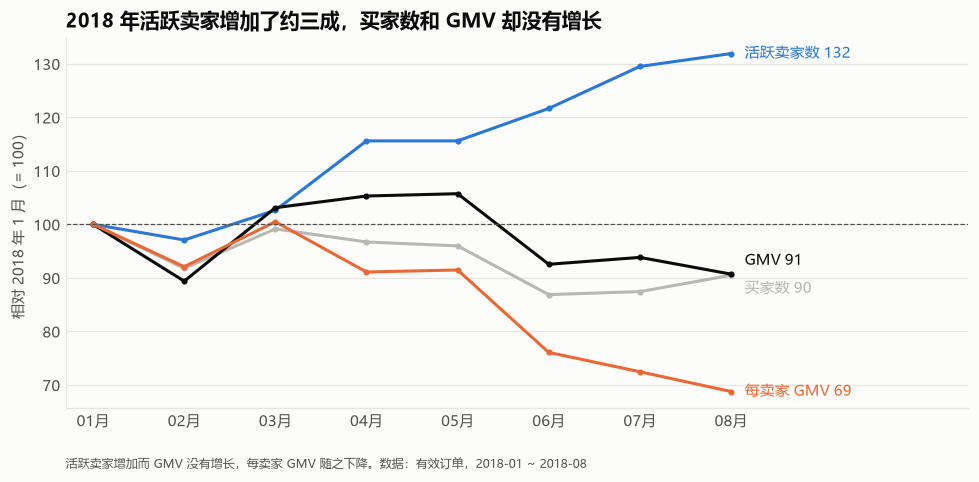

In [10]:
# 图：2018 年各指标相对 1 月的变化（1 月 = 100）
idx = m18[["active_sellers", "buyers", "gmv", "gmv_per_seller"]].astype(float)
idx = idx / idx.iloc[0] * 100
labels = {"active_sellers": "活跃卖家数", "buyers": "买家数", "gmv": "GMV", "gmv_per_seller": "每卖家 GMV"}
styles = {"active_sellers": (COLORS["blue"], "-"), "buyers": (COLORS["gray"], "-"),
          "gmv": (COLORS["text"], "-"), "gmv_per_seller": (COLORS["orange"], "-")}

label_offset = {"active_sellers": 0, "buyers": -2.5, "gmv": 2.5, "gmv_per_seller": 0}   # 买家数与 GMV 终点接近，标签上下错开

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(idx))
for col in ["active_sellers", "buyers", "gmv", "gmv_per_seller"]:
    c, ls = styles[col]
    ax.plot(x, idx[col], color=c, linestyle=ls, marker="o", markersize=3)
    ax.text(x[-1] + 0.15, idx[col].iloc[-1] + label_offset[col], f"{labels[col]} {idx[col].iloc[-1]:.0f}",
            va="center", fontsize=9.5, color=c)
ax.axhline(100, color=COLORS["text_secondary"], linewidth=0.8, linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels([m[5:] + "月" for m in idx.index])
ax.set_xlim(-0.3, len(idx) + 1.6)
ax.set_ylabel("相对 2018 年 1 月（= 100）")
ax.set_title("2018 年活跃卖家增加了约三成，买家数和 GMV 却没有增长", loc="left")
ax.text(0, -0.16, "活跃卖家增加而 GMV 没有增长，每卖家 GMV 随之下降。数据：有效订单，2018-01 ~ 2018-08",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])
fig.tight_layout()
fig.savefig("../docs/figures/s2_seller_side.png", dpi=150, bbox_inches="tight")
plt.show()

**结论：**
- 2018 年 GMV 停滞，是因为**买家需求没有增长**，而不是卖家供给不足：活跃卖家增加 32%，每个卖家的平均 GMV 下降 31%
- 2018 年新出现的卖家占 2018 年活跃卖家的 54%，只贡献了 30% 的 GMV；它们的平均 GMV 约为老卖家的三分之一
- 这和模块7 的发现可以连起来理解：签约的卖家很多没有起步，即使起步，也是在分同一块需求。**2018 年卖家数量的增加没有带来 GMV 的增长**，卖家获取的价值在于卖家质量（体验更好、品类补缺），而不是数量

**对报告的影响：** 增长诊断章节同时给出买家侧和卖家侧两种拆解，结论从"增长依赖拉新"细化为"增长受需求限制，新增卖家在分存量"。

## 3. "延误第 4 天是临界点"成立吗？

模块3 有两个结果，当时分别解读：
- 3.2：差评率从晚 1~3 天的 32.1% 跳到晚 4~7 天的 67.7%，解读为"买家能容忍 3 天以内的延误"，并据此建议对晚 3 天仍未送达的订单主动干预
- 3.5（S4）：延误订单的评价中约 74% 写于收货之前

如果"收货前评价"的比例也恰好在第 4 天前后跳升，那么差评率的跳升可能只是**评价时点**的变化，而不是买家容忍度的变化。按 3.2 的同一分组，把两者放在一起看。

In [11]:
sql_bucket = '''
SELECT CASE WHEN delay_days <= -8 THEN '1 提前8天以上'
            WHEN delay_days <= -1 THEN '2 提前1~7天'
            WHEN delay_days =   0 THEN '3 承诺当天'
            WHEN delay_days <=  3 THEN '4 晚1~3天'
            WHEN delay_days <=  7 THEN '5 晚4~7天'
            WHEN delay_days <= 14 THEN '6 晚8~14天'
            ELSE                       '7 晚15天以上' END                                  AS bucket,
       SUM(has_review)                                                                     AS n_reviewed,
       AVG(CASE WHEN has_review = 1 THEN is_review_before_delivery END)                    AS pre_share,
       AVG(is_bad_review)                                                                  AS bad_all,
       SUM(CASE WHEN has_review = 1 AND is_review_before_delivery = 0 THEN 1 ELSE 0 END)  AS n_post,
       SUM(CASE WHEN is_review_before_delivery = 0 THEN is_bad_review ELSE 0 END)         AS bad_post_n
FROM dws_order_fulfillment
GROUP BY bucket
ORDER BY bucket
'''
bk = run_query(sql_bucket)
for c in ["n_reviewed", "pre_share", "bad_all", "n_post", "bad_post_n"]:
    bk[c] = bk[c].astype(float)
bk["bad_post"] = bk["bad_post_n"] / bk["n_post"].replace(0, np.nan)
bk[["bucket", "n_reviewed", "pre_share", "bad_all", "n_post", "bad_post"]].round(3)

,bucket,n_reviewed,pre_share,bad_all,n_post,bad_post
0,1 提前8天以上,70673.0,0.002,0.090,70515.0,0.089
1,2 提前1~7天,17229.0,0.003,0.102,17174.0,0.102
2,3 承诺当天,1280.0,0.006,0.124,1272.0,0.123
3,4 晚1~3天,1851.0,0.208,0.321,1465.0,0.248
4,5 晚4~7天,1748.0,0.907,0.677,163.0,0.276
5,6 晚8~14天,1446.0,0.999,0.802,1.0,0.000
6,7 晚15天以上,1333.0,1.000,0.783,0.0,NaN


**观察：** 收货前评价的比例在晚 1~3 天时约 21%，到晚 4~7 天跳到约 91%，晚 8 天以上几乎 100%，**和差评率的跳升发生在同一个位置**。只看收货后写的评价，晚 1~3 天和晚 4~7 天的差评率相差不多。

两点需要确认：
1. 晚 4~7 天组收货后的评价只有一百多条，差别是否只是样本小造成的？用置信区间检查
2. 为什么延误越久，评价越可能写在收货前？看评价的产生时间

In [12]:
def wilson(k, n, z=1.96):
    '''比例的 Wilson 置信区间（小样本、比例接近 0 或 1 时比正态近似更可靠）'''
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

ci = bk.apply(lambda r: wilson(r["bad_post_n"], r["n_post"]), axis=1, result_type="expand")
bk["post_lo"], bk["post_hi"] = ci[0], ci[1]
bk[["bucket", "n_post", "bad_post", "post_lo", "post_hi"]].round(3)

,bucket,n_post,bad_post,post_lo,post_hi
0,1 提前8天以上,70515.0,0.089,0.087,0.091
1,2 提前1~7天,17174.0,0.102,0.097,0.107
2,3 承诺当天,1272.0,0.123,0.106,0.142
3,4 晚1~3天,1465.0,0.248,0.227,0.271
4,5 晚4~7天,163.0,0.276,0.213,0.349
5,6 晚8~14天,1.0,0.000,0.000,0.793
6,7 晚15天以上,0.0,NaN,NaN,NaN


In [13]:
# 评价的产生时间（review_creation_date，Olist 数据说明：满意度问卷发出的日期）
# 分别与"承诺送达日"和"实际送达日"比较
sql_timing = '''
SELECT f.is_late,
       DATEDIFF(r.review_creation_date, DATE(o.estimated_delivery_date)) AS days_from_promise,
       DATEDIFF(r.review_creation_date, DATE(o.delivered_customer_ts))   AS days_from_delivery
FROM dws_order_fulfillment f
JOIN dwd_order_reviews r ON f.order_id = r.order_id
JOIN dwd_orders o        ON f.order_id = o.order_id
'''
tm = run_query(sql_timing)
desc = tm.groupby("is_late")[["days_from_promise", "days_from_delivery"]].quantile([0.1, 0.5, 0.9]).unstack()
desc.index = ["未延误", "延误"]
desc

days_from_promise            days_from_delivery          
                  0.1   0.5  0.9                0.1  0.5  0.9
未延误             -21.0 -12.0 -4.0                1.0  1.0  1.0
延误                2.0   2.0  4.0              -20.0 -4.0  1.0

**观察：**
- 未延误订单：评价几乎都在**实际送达后 1 天**产生
- 延误订单：评价在**承诺送达日后 2~4 天**产生，此时多数订单还没送达（中位数为送达前 4 天）

这与 Olist 数据集说明一致：买家收到商品，**或承诺送达日已到**，平台就会发出满意度问卷。延误的订单在问卷到达时还没收到货，延误越久，收货前作答的比例越高。

因此 3.2 中差评率的跳升，主要反映的是"问卷到达时货到了没有"，而不是"晚了几天"。下面把两种口径画在一起。

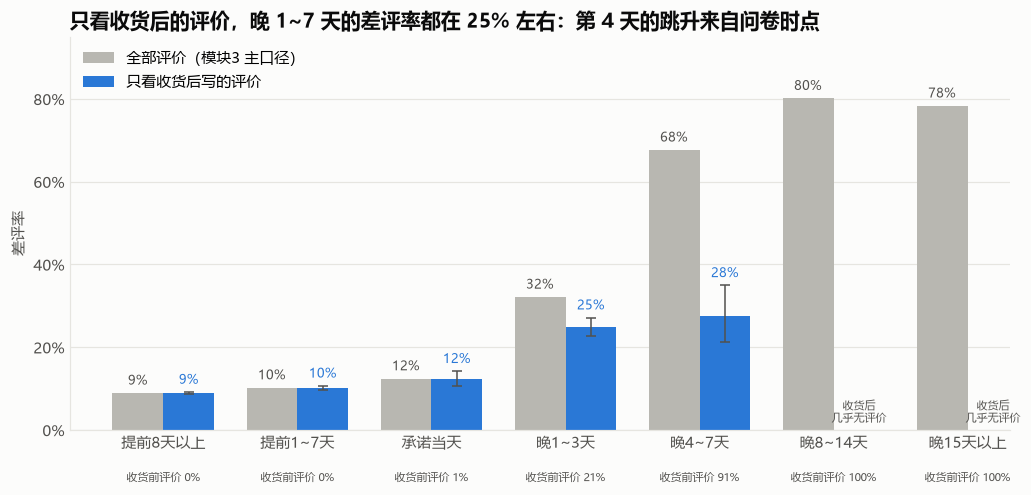

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(bk))
w = 0.38
ax.bar(x - w / 2, bk["bad_all"], width=w, color=COLORS["gray"], label="全部评价（模块3 主口径）")
ok = bk["n_post"] >= 30                                   # 收货后评价不足 30 条的组不画
ax.bar(x[ok] + w / 2, bk.loc[ok, "bad_post"], width=w, color=COLORS["blue"], label="只看收货后写的评价")
ax.errorbar(x[ok] + w / 2, bk.loc[ok, "bad_post"],
            yerr=[bk.loc[ok, "bad_post"] - bk.loc[ok, "post_lo"], bk.loc[ok, "post_hi"] - bk.loc[ok, "bad_post"]],
            fmt="none", ecolor=COLORS["text_secondary"], elinewidth=1, capsize=3)
for xi, r in zip(x, bk.itertuples()):
    ax.text(xi - w / 2, r.bad_all + 0.02, f"{r.bad_all:.0%}", ha="center", fontsize=8.5, color=COLORS["text_secondary"])
    if r.n_post >= 30:
        ax.text(xi + w / 2, r.post_hi + 0.02, f"{r.bad_post:.0%}", ha="center", fontsize=8.5, color=COLORS["blue"])
    else:
        ax.text(xi + w / 2, 0.02, "收货后\n几乎无评价", ha="center", fontsize=7.5, color=COLORS["text_secondary"])
    ax.text(xi, -0.13, f"收货前评价 {r.pre_share:.0%}", ha="center", fontsize=7.5, color=COLORS["text_secondary"],
            transform=ax.get_xaxis_transform())
ax.set_xticks(x)
ax.set_xticklabels([b[2:] for b in bk["bucket"]])
ax.set_ylim(0, 0.95)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("差评率")
ax.legend(loc="upper left", frameon=False)
ax.set_title("只看收货后的评价，晚 1~7 天的差评率都在 25% 左右：第 4 天的跳升来自问卷时点", loc="left")
fig.tight_layout()
fig.savefig("../docs/figures/s2_review_timing.png", dpi=150, bbox_inches="tight")
plt.show()

**结论：**
- "延误第 4 天是临界点"**不成立**：跳升的位置正是问卷改为在收货前到达的位置。只看收货后的评价，晚 1~3 天和晚 4~7 天的差评率没有显著差别（置信区间重叠）
- 买家给差评的关键时刻是**问卷到达时货有没有到**，也就是承诺送达日当天。一旦错过承诺日，晚几天的差别不大
- 3.5 的主口径（保留收货前的评价）仍然合理：这些评价是买家"到了承诺日还没收到货"的真实反应。但延误对差评的影响应给出区间：全部评价口径为上限，只看收货后评价为下限（D-036）

**对报告和建议的影响：**
- 删除"对晚 3 天仍未送达的订单主动干预"的建议，它的依据不成立
- 关键不是延误几天，而是**承诺日期能否兑现**。下一节沿着这个线索，重新检查延误集中的那几个月

## 4. 延误集中的月份：是订单高峰，还是承诺失准？

模块3 3.6 把月度延误率超过 10% 的 3 个月（2017-11、2018-02、2018-03）称为"高峰月"（D-032），阶段2 据此建议"为高峰期准备物流运力预案"。这个建议隐含了两个假设：这几个月订单特别多；延误是运力不足造成的。第 3 节又发现差评的关键在于承诺日期能否兑现。这里逐一检查。

### 4.1 这几个月是订单高峰吗？

In [15]:
sql_month = '''
SELECT purchase_month,
       COUNT(*)                              AS orders,
       AVG(is_late)                          AS late_rate,
       AVG(seller_days)                      AS seller_days,     -- 卖家处理：下单 → 交给物流
       AVG(transit_days)                     AS transit_days,    -- 物流运输：交给物流 → 送达
       AVG(delivery_days)                    AS delivery_days,   -- 实际配送：下单 → 送达
       AVG(delivery_days - delay_days)       AS promise_days     -- 承诺配送：下单 → 承诺送达日
FROM dws_order_fulfillment
GROUP BY purchase_month
ORDER BY purchase_month
'''
mon = run_query(sql_month)
for c in mon.columns[1:]:
    mon[c] = mon[c].astype(float)
HIGH_DELAY = ["2017-11", "2018-02", "2018-03"]            # D-032 的定义：月度延误率 > 10%
mon["high_delay"] = mon["purchase_month"].isin(HIGH_DELAY)
mon["orders_rank"] = mon["orders"].rank(ascending=False).astype(int)
print(f"月度订单量与延误率的相关系数：{np.corrcoef(mon['orders'], mon['late_rate'])[0, 1]:.2f}")
mon[["purchase_month", "orders", "orders_rank", "late_rate", "high_delay"]].round(3)

月度订单量与延误率的相关系数：0.51


,purchase_month,orders,orders_rank,late_rate,high_delay
0,2017-01,750.0,20,0.029,False
1,2017-02,1653.0,19,0.030,False
2,2017-03,2546.0,17,0.046,False
3,2017-04,2303.0,18,0.066,False
4,2017-05,3545.0,15,0.030,False
5,2017-06,3135.0,16,0.030,False
6,2017-07,3872.0,14,0.028,False
7,2017-08,4193.0,12,0.029,False
8,2017-09,4150.0,13,0.044,False
9,2017-10,4478.0,11,0.042,False


**观察：** 订单量与延误率有一定相关（0.51），因为 2017-11 到 2018-03 订单量整体偏高。但逐月看：只有 2017-11（黑色星期五）是订单最多的月份；2018-02、2018-03 的订单量都**低于** 2018-01（排名第 2），而 2018-01 的延误率只有 5.7%。订单量解释不了这几个月的延误，"高峰月"这个名称并不准确，以下改称"高延误月"（D-035）。

### 4.2 是哪一段变慢了？

把配送拆成卖家处理和物流运输两段，并和承诺的配送天数对比。

In [16]:
mon[["purchase_month", "late_rate", "seller_days", "transit_days", "delivery_days", "promise_days"]].round(2)

,purchase_month,late_rate,seller_days,transit_days,delivery_days,promise_days
0,2017-01,0.03,2.96,9.19,12.75,40.16
1,2017-02,0.03,3.29,9.54,13.30,32.50
2,2017-03,0.05,2.94,9.80,13.04,25.37
3,2017-04,0.07,3.20,11.22,15.02,27.99
4,2017-05,0.03,2.61,8.32,11.43,24.92
5,2017-06,0.03,2.71,8.83,12.01,24.66
6,2017-07,0.03,2.56,8.48,11.49,23.96
7,2017-08,0.03,2.48,8.05,11.02,24.11
8,2017-09,0.04,2.56,8.64,11.72,23.07
9,2017-10,0.04,2.83,8.41,11.73,23.66


**观察：**
- 高延误月的**物流运输时长明显变长**（11~13 天，前后几个月约 8~9 天）；卖家处理时长只多了不到 1 天
- 承诺的配送天数**没有相应延长**，2018-03 甚至比平常更短
- 2017-12、2018-01 是一组对照：运输同样变慢（10~12 天），但承诺天数延长到约 27~28 天，延误率只有 7.5% 和 5.7%

这提示延误率由"承诺时长"与"实际配送时长"之间的**缓冲**决定，而不是由订单量或运输时长单独决定。

比较之前先排除平台起步期 2017-01~04：这几个月每月订单不到 2,600 单，承诺天数异常长（25~40 天），与之后的月份不可比。以下比较 2017-05 ~ 2018-08。

2018-06~08 的配送天数明显变短。先确认这不是因为下单较晚的订单还没送达、被排除在有效订单之外（右删失）：

In [17]:
status = run_query('''
SELECT purchase_month,
       COUNT(*)                          AS orders_all_status,
       AVG(order_status = 'delivered')   AS delivered_share
FROM dwd_orders
WHERE in_analysis_window = 1 AND purchase_month >= '2017-05'
GROUP BY purchase_month
ORDER BY purchase_month
''')
status["delivered_share"] = status["delivered_share"].astype(float)
status.round(3).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
purchase_month,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders_all_status,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512
delivered_share,0.958,0.966,0.962,0.968,0.968,0.967,0.966,0.972,0.972,0.974,0.971,0.98,0.982,0.989,0.979,0.975


**观察：** 2018-06~08 下单的订单中已送达的比例为 97.5%~98.9%，与其他月份相当，说明是物流真的变快了，不是右删失造成的，可以纳入比较。

In [18]:
mon["buffer"] = mon["promise_days"] - mon["delivery_days"]   # 缓冲：承诺比实际多出的天数
cmp = mon[mon["purchase_month"] >= "2017-05"].reset_index(drop=True)
for col, name in [("orders", "订单量"), ("seller_days", "卖家处理时长"), ("transit_days", "运输时长"), ("buffer", "缓冲天数")]:
    print(f"月度延误率与{name}的相关系数：{np.corrcoef(cmp[col], cmp['late_rate'])[0, 1]:+.2f}")
period = np.where(cmp["high_delay"], "高延误月", "其他月份")
cmp.groupby(period)[["orders", "late_rate", "seller_days", "transit_days", "delivery_days", "promise_days", "buffer"]].mean().round(2)

月度延误率与订单量的相关系数：+0.57
月度延误率与卖家处理时长的相关系数：+0.54
月度延误率与运输时长的相关系数：+0.78
月度延误率与缓冲天数的相关系数：-0.79


,orders,late_rate,seller_days,transit_days,delivery_days,promise_days,buffer
其他月份,5238.85,0.04,2.56,8.28,11.32,24.00,12.68
高延误月,6948.67,0.15,3.08,12.49,16.06,23.68,7.61


**观察：**
- 订单量与延误率的相关不弱（+0.57）：订单多的月份，运输也更容易变慢，所以运力紧张**可能是运输变慢的原因之一**，不能排除
- 与延误率关系最紧密的是运输时长（+0.78）和**缓冲天数**（−0.79）：高延误月的平均缓冲只有约 7.6 天，其他月份约 12.7 天
- 订单量同样很高的 2018-01（7,069 单），因为承诺放宽、缓冲保持在约 13 天，延误率只有 5.7%。这说明即使运输变慢，只要承诺跟着调整，延误就可以避免

但有一个例外：2018-08 的缓冲只有约 8 天，和高延误月差不多，延误率却只有 6%。可能的原因是，延误与否不只取决于平均缓冲，还取决于配送时长的**波动**：波动小时，较短的缓冲也够用。下面把缓冲除以当月配送时长的标准差（"相对缓冲"），再检验一次。

In [19]:
sd = run_query('''
SELECT purchase_month, STDDEV(delivery_days) AS delivery_sd
FROM dws_order_fulfillment
WHERE purchase_month >= '2017-05'
GROUP BY purchase_month
''')
sd["delivery_sd"] = sd["delivery_sd"].astype(float)
cmp = cmp.drop(columns=[c for c in ["delivery_sd", "rel_buffer"] if c in cmp.columns]).merge(sd, on="purchase_month")
cmp["rel_buffer"] = cmp["buffer"] / cmp["delivery_sd"]          # 缓冲相当于几个标准差
print(f"月度延误率与缓冲天数的相关系数：{np.corrcoef(cmp['buffer'], cmp['late_rate'])[0, 1]:+.2f}")
print(f"月度延误率与相对缓冲的相关系数：{np.corrcoef(cmp['rel_buffer'], cmp['late_rate'])[0, 1]:+.2f}")
cmp.loc[cmp["purchase_month"].isin(["2017-11", "2018-02", "2018-03", "2018-08"]),
        ["purchase_month", "late_rate", "buffer", "delivery_sd", "rel_buffer"]].round(2)

月度延误率与缓冲天数的相关系数：-0.79
月度延误率与相对缓冲的相关系数：-0.84


,purchase_month,late_rate,buffer,delivery_sd,rel_buffer
6,2017-11,0.12,8.12,10.75,0.76
9,2018-02,0.14,8.29,11.98,0.69
10,2018-03,0.19,6.43,11.46,0.56
15,2018-08,0.06,8.16,4.37,1.87


**观察：** 2018-08 的配送时长波动很小（标准差约 4.4 天，高延误月约 11~12 天），8 天的缓冲相当于约 1.9 个标准差，和平常月份相近；高延误月只有 0.6~0.8 个标准差。用相对缓冲衡量，与延误率的相关更强（−0.84）。机制不变，而且更完整：**运输变慢时，配送时长的波动也同时变大，承诺需要放宽得更多。**

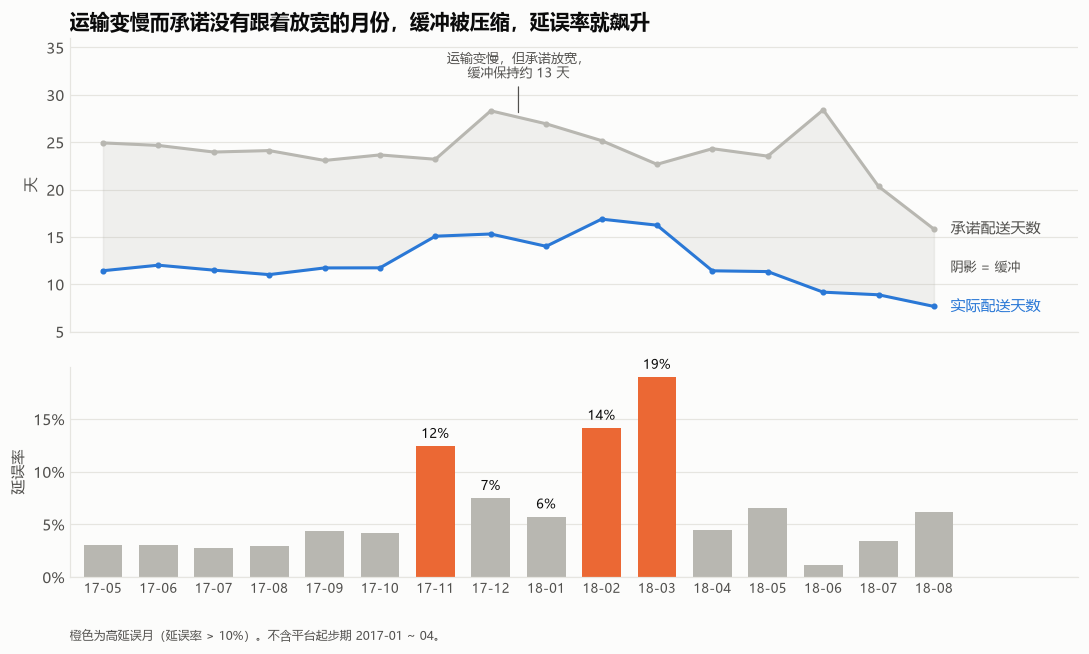

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
x = np.arange(len(cmp))
ax1.fill_between(x, cmp["delivery_days"], cmp["promise_days"], color=COLORS["gray"], alpha=0.18)
ax1.plot(x, cmp["promise_days"], color=COLORS["gray"], marker="o", markersize=3)
ax1.plot(x, cmp["delivery_days"], color=COLORS["blue"], marker="o", markersize=3)
ax1.text(x[-1] + 0.3, cmp["promise_days"].iloc[-1], "承诺配送天数", va="center", fontsize=9.5, color=COLORS["text_secondary"])
ax1.text(x[-1] + 0.3, cmp["delivery_days"].iloc[-1], "实际配送天数", va="center", fontsize=9.5, color=COLORS["blue"])
ax1.text(x[-1] + 0.3, cmp[["promise_days", "delivery_days"]].iloc[-1].mean(), "阴影 = 缓冲",
         va="center", fontsize=8.5, color=COLORS["text_secondary"])
i12 = int(cmp.index[cmp["purchase_month"] == "2017-12"][0])
ax1.annotate("运输变慢，但承诺放宽，\n缓冲保持约 13 天", xy=(i12 + 0.5, 27.8), xytext=(i12 + 0.5, 33),
             fontsize=8.5, color=COLORS["text_secondary"], ha="center", va="center",
             arrowprops=dict(arrowstyle="-", color=COLORS["text_secondary"], lw=0.8))
ax1.set_ylabel("天")
ax1.set_ylim(5, 36)
ax1.set_title("运输变慢而承诺没有跟着放宽的月份，缓冲被压缩，延误率就飙升", loc="left")

colors = [COLORS["orange"] if h else COLORS["gray"] for h in cmp["high_delay"]]
ax2.bar(x, cmp["late_rate"], color=colors, width=0.7)
for xi, r in zip(x, cmp.itertuples()):
    if r.high_delay or r.purchase_month in ["2017-12", "2018-01"]:
        ax2.text(xi, r.late_rate + 0.008, f"{r.late_rate:.0%}", ha="center", fontsize=8.5, color=COLORS["text"])
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax2.set_ylabel("延误率")
ax2.set_xticks(x)
ax2.set_xticklabels([m[2:] for m in cmp["purchase_month"]], fontsize=8.5)
ax2.set_xlim(-0.6, len(cmp) + 1.6)
ax2.text(0, -0.3, "橙色为高延误月（延误率 > 10%）。不含平台起步期 2017-01 ~ 04。",
         transform=ax2.transAxes, fontsize=8, color=COLORS["text_secondary"])
fig.tight_layout()
fig.savefig("../docs/figures/s2_promise_vs_transit.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 如果承诺日期跟着运输时长调整，能少多少延误？

2017-12、2018-01 提供了现成的做法：运输变慢时放宽承诺，让缓冲保持在平常水平。假设高延误月也这样做：每个高延误月的承诺放宽到"缓冲恢复到平常月的平均水平"，那么晚于原承诺、但晚得不超过放宽天数的订单，就会变为按时送达。平常水平取 2017-05 ~ 2018-08 中非高延误月缓冲的中位数（2018-06 的缓冲约 19 天，偏高，用中位数避免被它拉高）。

In [21]:
normal_buffer = cmp.loc[~cmp["high_delay"], "buffer"].median()
ext = cmp.loc[cmp["high_delay"], ["purchase_month", "buffer"]].copy()
ext["extend_days"] = (normal_buffer - ext["buffer"]).round().astype(int)     # 每个高延误月需要放宽的天数
print(f"平常月缓冲（中位数）{normal_buffer:.1f} 天")
print(ext.round(1).to_string(index=False))

hd_list = ", ".join(f"'{m}'" for m in HIGH_DELAY)
sql_hd = f'''
SELECT purchase_month, delay_days
FROM dws_order_fulfillment
WHERE purchase_month IN ({hd_list}) AND is_late = 1
'''
hd = run_query(sql_hd).merge(ext[["purchase_month", "extend_days"]], on="purchase_month")
hd["avoided"] = hd["delay_days"] <= hd["extend_days"]
LATE_AVOIDED_PROMISE = int(hd["avoided"].sum())
print(f"\n高延误月延误订单 {len(hd):,} 单，其中 {LATE_AVOIDED_PROMISE:,} 单（{hd['avoided'].mean():.0%}）会变为按时送达")
hd.groupby("purchase_month")["avoided"].agg(late_orders="size", avoided="sum", share="mean").round(2)

平常月缓冲（中位数）12.6 天
purchase_month  buffer  extend_days
       2017-11     8.1            5
       2018-02     8.3            4
       2018-03     6.4            6

高延误月延误订单 3,158 单，其中 1,223 单（39%）会变为按时送达


,late_orders,avoided,share
purchase_month,,,
2017-11,904,357,0.39
2018-02,926,270,0.29
2018-03,1328,596,0.45


**结论：**
- 3 个高延误月中，只有 2017-11 是订单高峰；2018-02、2018-03 的订单量都低于 2018-01。"高峰月"改称"**高延误月**"（D-035）
- 延误率的变化主要由**物流运输变慢、而承诺天数没有跟着调整**造成，卖家处理时长变化很小。运输变慢可能与订单量大有关，但平台能直接控制的是承诺日期：2017-12、2018-01 运输同样变慢，承诺放宽后延误率保持在低位，是现成的对照
- 2018-08 缓冲同样较窄但延误率不高，是因为当月配送时长波动小；按"缓冲 ÷ 配送时长标准差"衡量，与延误率的相关系数为 −0.84，机制成立
- 这个解释不依赖"延误率 > 10%"的定义：运输时长和承诺天数都不是由延误率算出来的，所以不是"按结果挑月份再解释结果"
- 如果高延误月的承诺跟着运输时长放宽（4~6 天）、保持平常的缓冲，3,158 单延误中约 1,223 单（39%）会变为按时送达
- 局限：运输为什么在这几个月变慢（承运商运力、天气、罢工等），现有数据无法回答；承诺天数变长可能降低下单转化，这个代价数据中看不到，需要实验验证

**对报告和建议的影响：** 建议从"为高峰期准备运力预案"改为"**按运输时长动态校准承诺送达日期**"：监控各线路的运输时长，变慢时自动放宽承诺。对应杠杆在 `s2_impact_sizing` 中重新测算。

## 5. 多件订单为什么差评多？

模块3 3.7 发现：只看准时送达的订单，单件订单差评率 7.5%，多件同一卖家 21.0%，多件多个卖家 46.9%；它是延误之外最大的差评来源，但原因"现有数据无法确认，需要分析评论文本"。`dwd_order_reviews.review_comment_message` 中保存了买家的评论文本（葡萄牙语），这里尝试用它回答。

### 5.1 评论的覆盖情况

先看评论够不够用：准时送达的订单中，各组有多少评价附带了文字评论。

In [22]:
sql_comments = '''
SELECT f.order_id,
       CASE WHEN f.n_items = 1       THEN '单件'
            WHEN f.is_multi_seller = 1 THEN '多件-多卖家'
            ELSE                            '多件-同一卖家' END AS grp,
       f.is_bad_review,
       r.has_comment,
       r.review_comment_message AS msg
FROM dws_order_fulfillment f
JOIN dwd_order_reviews r ON f.order_id = r.order_id
WHERE f.is_late = 0
ORDER BY f.order_id
'''
cm = run_query(sql_comments)
GROUP_ORDER = ["单件", "多件-同一卖家", "多件-多卖家"]
coverage = cm.groupby(["grp", "is_bad_review"]).agg(reviews=("has_comment", "size"), comment_rate=("has_comment", "mean"))
coverage.round(3)

reviews  comment_rate
grp     is_bad_review                       
单件      0                74140         0.350
        1                 6034         0.752
多件-同一卖家 0                 6133         0.372
        1                 1629         0.870
多件-多卖家  0                  662         0.471
        1                  584         0.848

**观察：** 差评附带评论的比例很高（单件 75%，多件 85% 以上），足够分析。下面只看**准时送达、差评、有评论**的订单。

### 5.2 多件订单的差评都在说什么？

不预设原因，先比较词频：每个词在多件订单差评评论中出现的比例，除以它在单件订单差评评论中出现的比例。比值越高，越是多件订单特有的抱怨。（统一转小写、去掉重音符号，只统计 3 个字母以上的词；每条评论中一个词只计一次。）

In [23]:
bad = cm[(cm["is_bad_review"] == 1) & (cm["has_comment"] == 1)].copy()

def normalize(text):
    '''转小写并去掉重音符号：não → nao, só → so'''
    text = unicodedata.normalize("NFKD", text.lower())
    return "".join(ch for ch in text if not unicodedata.combining(ch))

bad["text"] = bad["msg"].map(normalize)
bad["words"] = bad["text"].map(lambda t: set(re.findall(r"[a-z]{3,}", t)))
bad["is_multi"] = bad["grp"] != "单件"

n_multi, n_single = bad["is_multi"].sum(), (~bad["is_multi"]).sum()
cnt_multi = Counter(w for ws in bad.loc[bad["is_multi"], "words"] for w in ws)
cnt_single = Counter(w for ws in bad.loc[~bad["is_multi"], "words"] for w in ws)
freq = pd.DataFrame([(w, c / n_multi, cnt_single[w] / n_single) for w, c in cnt_multi.items() if c / n_multi >= 0.03],
                    columns=["word", "share_multi", "share_single"])
freq["ratio"] = (freq["share_multi"] + 0.002) / (freq["share_single"] + 0.002)   # 加一个小数，避免除以 0
print(f"多件订单差评评论 {n_multi:,} 条，单件 {n_single:,} 条")
freq.sort_values("ratio", ascending=False).head(25).round(3)

多件订单差评评论 1,912 条，单件 4,537 条


,word,share_multi,share_single,ratio
20,unidades,0.075,0.003,15.891
27,unidade,0.038,0.002,11.193
4,dois,0.162,0.013,11.067
16,apenas,0.207,0.017,10.772
7,somente,0.089,0.009,8.122
1,duas,0.103,0.013,7.105
53,itens,0.041,0.004,7.001
5,produtos,0.137,0.020,6.303
63,foram,0.034,0.005,5.092
51,faltando,0.065,0.018,3.320


**观察：** 多件订单特有的词集中在三类：
- 数量：dois / duas（两个）、unidades（件）、itens / produtos（商品）
- "只有"：apenas / somente（仅仅、只）
- 缺少：faltando / falta（缺）、consta（显示为）、nota fiscal（发票上列了几件）

拼起来就是"我买了两件，**只**收到一件"、"**缺**了一件"。这提示多件订单的差评主要来自**收货不完整**。下面把它写成规则，再人工抽查规则是否可靠。

### 5.3 规则与抽查

一条评论满足以下任一条件，记为"收货不完整"：
1. 出现"缺"：falta / faltando / faltou / faltaram / faltam
2. 同时出现"只"（apenas / somente / so）和"收到 / 送来"类动词（recebi / veio / vieram / chegou / chegaram / entregaram / entregue / enviaram / mandaram）

In [24]:
MISSING = r"\bfalt(?:a|ando|ou|aram|am)\b"
ONLY = r"\b(?:apenas|somente|so)\b"
RECEIVED = r"\b(?:recebi|recebemos|veio|vieram|chegou|chegaram|entregaram|entregue|enviaram|mandaram)\b"
bad["incomplete"] = bad["text"].str.contains(MISSING) | (bad["text"].str.contains(ONLY) & bad["text"].str.contains(RECEIVED))

pd.set_option("display.max_colwidth", 160)
for g, n in [("多件-同一卖家", 15), ("多件-多卖家", 15), ("单件", 10)]:
    sample = bad[(bad["grp"] == g) & bad["incomplete"]].sample(n, random_state=42)
    print(f"===== {g}：随机抽取 {n} 条被规则匹配的评论")
    for i, m in enumerate(sample["msg"], 1):
        print(i, m.replace("\n", " ")[:160])

===== 多件-同一卖家：随机抽取 15 条被规则匹配的评论
1 EFETUEI A COMPRA DE TRES UNIDADES E APENAS RECEBI UMA, COMO VAI FICAR OS OUTROS Q JA PAGUEI?
2 Não recebi toda a mercadoria, comprei dois cartuchos de tinta hp e só recebi um. Ninguém não dá nem um sinal para resolver o problema. Estou vendo que vou ter q
 Estou preoa não chegou o outro filtro.idade) , Falta entregar o outro produto que Comprei.
4 Preciso resolver um.problema comprei dois produtos mais recebi apenas um
5 Pedi dois kit veio so um, fora que eu paguei pelos dois 
6 Eu comprei 2 MOP, e no mesmo dia solicitei a devolução, não tive resposta ainda, de como devolver, e ainda por cima chegou apenas 1 na minha casa.
7 comprei dois produtos so me entregaram um
8 Recebi o produto incompleto!! Realizei a compra de.2 portas-retratos e no entanto só veio 1 porta retrato no pacote. Estou tentando entrar em contato com lannis
9 Fiz a compra de 3 peças. Como um produto era vendido em 2 unid, ao receber apenas duas caixas achei que estaria 2 produtos em 

**抽查结果（人工阅读上面的评论）：** 多件订单的 30 条全部在说收货不完整，例如"买了 3 件只收到 1 件"、"买了两个，只送来一个，却按两个收了钱"、"缺了一件，物流显示已送达"。单件订单被匹配的 10 条中，9 条是套装或组合商品缺部件、数量不足（如"买了底座加安全座椅的套装，只收到底座"），1 条是整件没收到。规则在各组都基本可靠。

规则会漏掉一些说法（例如只写"没收到另一件"），所以下面的比例是**下限**。

### 5.4 各组差评中"收货不完整"的比例

In [25]:
inc = bad.groupby("grp").agg(comments=("incomplete", "size"), incomplete=("incomplete", "sum"))
inc["share"] = inc["incomplete"] / inc["comments"]
inc = inc.loc[GROUP_ORDER]
inc.round(3)

,comments,incomplete,share
grp,,,
单件,4537,353,0.078
多件-同一卖家,1417,864,0.610
多件-多卖家,495,301,0.608


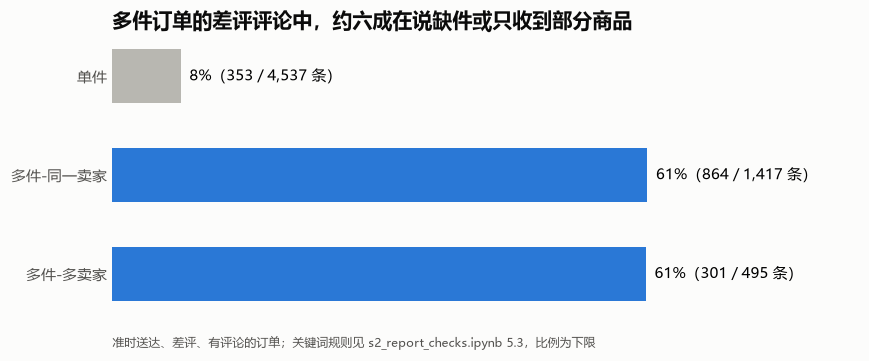

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(inc))[::-1]
ax.barh(y, inc["share"], color=[COLORS["gray"], COLORS["blue"], COLORS["blue"]], height=0.55)
for yi, r in zip(y, inc.itertuples()):
    ax.text(r.share + 0.01, yi, f"{r.share:.0%}（{r.incomplete:,} / {r.comments:,} 条）", va="center", fontsize=9.5)
ax.set_yticks(y)
ax.set_yticklabels(inc.index)
ax.set_xlim(0, 0.85)
ax.set_xticks([])
ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
ax.set_title("多件订单的差评评论中，约六成在说缺件或只收到部分商品", loc="left")
ax.text(0, -0.12, "准时送达、差评、有评论的订单；关键词规则见 s2_report_checks.ipynb 5.3，比例为下限",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])
fig.tight_layout()
fig.savefig("../docs/figures/s2_multi_incomplete.png", dpi=150, bbox_inches="tight")
plt.show()

**结论：**
- 多件订单差评高的主要原因是**收货不完整**：准时送达的多件订单差评评论中，约六成在说缺件或只收到部分商品，单件订单不到一成
- 很多评论提到"物流显示已送达，但只收到一部分"。数据中每笔订单只有一个送达时间，多件商品分包裹寄送时，第一个包裹送达后订单可能就被标记为"已送达"，后续包裹的状态无法追踪
- 局限：关键词规则会漏掉部分说法，比例为下限；无法区分"卖家漏发"和"分包裹后丢件 / 未到"

**对报告和建议的影响：** 多件订单不再是"原因未知、需先诊断"，杠杆改为"**多件订单完整交付**"：按包裹追踪，全部送达后才标记订单已送达；缺件时主动补发或退款（D-038）。

## 6. 卖家分层与渠道比较复核

### 6.1 逐个检验 575 个卖家，会有多少误判？

模块6 6.2 对样本充足（未延误有评价订单 ≥ 30）的卖家逐一判断：指标的 95% 置信区间下限高于平台平均，才判定为有问题（D-030）。报告初稿中写道"这样可以避免把小样本的偶然波动当成问题"。但这个判定对每个卖家各做一次：即使所有卖家其实都和平台一样，每次检验仍有约 2.5% 的概率误判（单侧），检验的卖家越多，误判的总数越多。

先看样本充足的卖家共有多少，以及各类问题卖家的数量。

In [27]:
tier = run_query('''
SELECT seller_id, is_head, problem_type, gmv,
       n_ot_reviewed, n_ot_bad, platform_ot_bad,
       n_ship_orders, n_seller_late, platform_seller_late
FROM ads_m6_seller_tier
WHERE problem_type IS NOT NULL
''')
for c in ["gmv", "n_ot_reviewed", "n_ot_bad", "platform_ot_bad", "n_ship_orders", "n_seller_late", "platform_seller_late"]:
    tier[c] = tier[c].astype(float)
tier["scope"] = np.where(tier["is_head"] == 1, "头部", "腰部")
pd.crosstab(tier["problem_type"], tier["scope"], margins=True, margins_name="合计")

scope,头部,腰部,合计
problem_type,,,
体验问题,21,4,25
健康,328,123,451
双重问题,19,4,23
时效问题,59,17,76
合计,427,148,575


In [28]:
n_tests = len(tier)
exp_flagged = tier["problem_type"].isin(["体验问题", "双重问题"]).sum()
time_flagged = tier["problem_type"].isin(["时效问题", "双重问题"]).sum()
print(f"样本充足的卖家 {n_tests} 个，每个指标各检验 {n_tests} 次")
print(f"假如所有卖家都和平台一样，每个指标预计仍会误判约 {n_tests * 0.025:.0f} 个（单侧 2.5%）")
print(f"实际判为有体验问题 {exp_flagged} 个，有时效问题 {time_flagged} 个")

样本充足的卖家 575 个，每个指标各检验 575 次
假如所有卖家都和平台一样，每个指标预计仍会误判约 14 个（单侧 2.5%）
实际判为有体验问题 48 个，有时效问题 99 个


**观察：**
- 范围说明：样本充足的卖家共 575 个，其中头部 427 个、腰部 148 个。模块6 的分层图画的是全部 575 个卖家（"两者兼有 23 个" = 头部 19 + 腰部 4），而治理建议针对的是头部 427 个。为了让图和文字范围一致，下面单独画一张头部卖家的分层图
- 预计误判约 14 个，相对于 48 个体验问题卖家不可忽视（时效问题有 99 个，影响相对小）。"置信区间下限"控制了单个卖家的误判，但没有控制**多次检验累积的误判**

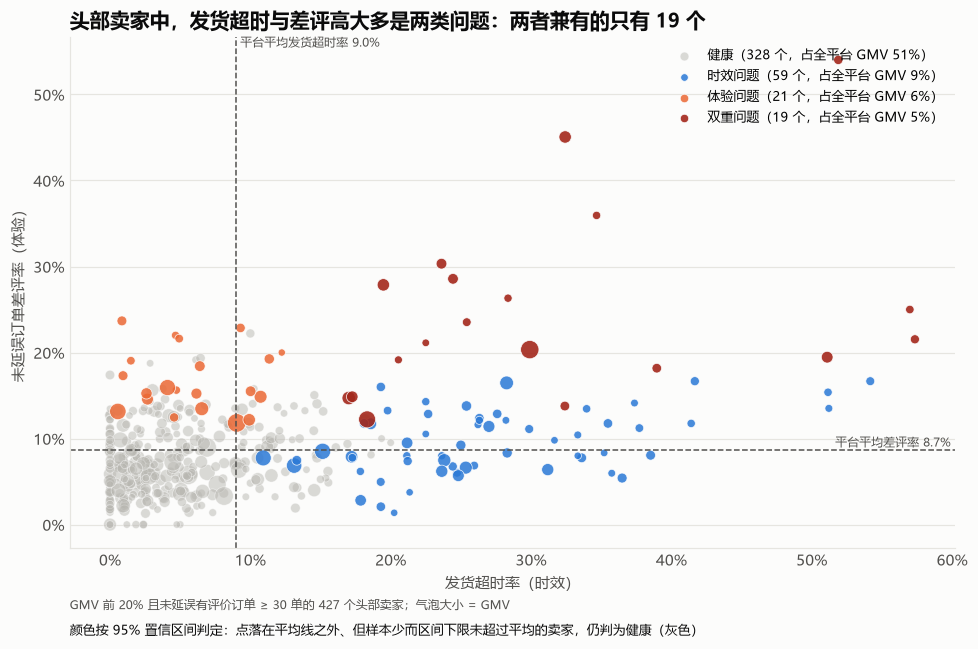

In [29]:
import matplotlib.ticker as mticker

hd_tier = run_query('''
SELECT problem_type, gmv, ot_bad_rate, seller_late_rate, platform_ot_bad, platform_seller_late
FROM ads_m6_seller_tier
WHERE is_head = 1 AND problem_type IS NOT NULL
''')
for c in ["gmv", "ot_bad_rate", "seller_late_rate", "platform_ot_bad", "platform_seller_late"]:
    hd_tier[c] = hd_tier[c].astype(float)
TOTAL_GMV = float(run_query("SELECT SUM(gmv) FROM ads_m6_seller_tier").iloc[0, 0])
p0, q0 = hd_tier["platform_ot_bad"].iloc[0], hd_tier["platform_seller_late"].iloc[0]

type_style = {"健康": (COLORS["gray"], 0.5), "时效问题": (COLORS["blue"], 0.85),
              "体验问题": (COLORS["orange"], 0.85), "双重问题": ("#a3271b", 0.9)}   # 与模块6 配色一致
fig, ax = plt.subplots(figsize=(9, 6))
for t, (color, alpha) in type_style.items():
    d = hd_tier[hd_tier["problem_type"] == t]
    ax.scatter(d["seller_late_rate"], d["ot_bad_rate"], s=np.sqrt(d["gmv"]) / 3, color=color, alpha=alpha,
               edgecolors="white", linewidths=0.5,
               label=f"{t}（{len(d)} 个，占全平台 GMV {d['gmv'].sum() / TOTAL_GMV:.0%}）")
ax.axvline(q0, color=COLORS["text_secondary"], linestyle="--", linewidth=1)
ax.axhline(p0, color=COLORS["text_secondary"], linestyle="--", linewidth=1)
ax.text(q0, 1.0, f" 平台平均发货超时率 {q0:.1%}", transform=ax.get_xaxis_transform(),
        fontsize=8, color=COLORS["text_secondary"], va="top")
ax.text(1.0, p0, f"平台平均差评率 {p0:.1%} ", transform=ax.get_yaxis_transform(),
        fontsize=8, color=COLORS["text_secondary"], ha="right", va="bottom")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("发货超时率（时效）")
ax.set_ylabel("未延误订单差评率（体验）")
ax.legend(frameon=False, loc="upper right", fontsize=8.5, markerscale=0.6)
n_both = (hd_tier["problem_type"] == "双重问题").sum()
ax.set_title(f"头部卖家中，发货超时与差评高大多是两类问题：两者兼有的只有 {n_both} 个", loc="left")
ax.text(0.0, -0.12, f"GMV 前 20% 且未延误有评价订单 ≥ 30 单的 {len(hd_tier)} 个头部卖家；气泡大小 = GMV",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])
ax.text(0.0, -0.17, "颜色按 95% 置信区间判定：点落在平均线之外、但样本少而区间下限未超过平均的卖家，仍判为健康（灰色）",
        transform=ax.transAxes, fontsize=8.5, color=COLORS["text"])
fig.tight_layout()
fig.savefig("../docs/figures/s2_seller_tier_head.png", dpi=150, bbox_inches="tight")
plt.show()

**读图：** 头部 427 个卖家中，健康 328 个、时效问题 59 个、体验问题 21 个、双重问题 19 个，与模块6 正文的数字一致。灰点出现在平均线之外并不是分类错误：这些卖家的指标虽然高于平均，但样本较少，95% 置信区间的下限没有超过平台平均，证据不足以判为有问题。

### 6.2 用多重比较校正重新判定

改用两个更严格的做法：
1. 用**精确二项检验**代替正态近似（模块6 的局限中提到"样本较小、比率接近 0 时正态近似不够精确"）
2. 用 **Benjamini-Hochberg（BH）校正**控制"被判为有问题的卖家中，误判的比例"不超过 5%

In [30]:
def bh_reject(p, q=0.05):
    '''Benjamini-Hochberg：p 值从小到大排序，第 k 个满足 p ≤ q·k/m 的最大 k 之前全部判为显著'''
    p = np.asarray(p)
    m = len(p)
    order = np.argsort(p)
    passed = p[order] <= q * np.arange(1, m + 1) / m
    k = passed.nonzero()[0].max() + 1 if passed.any() else 0
    reject = np.zeros(m, dtype=bool)
    reject[order[:k]] = True
    return reject

# 单侧精确检验：在平台平均水平下，出现至少这么多差评（超时）的概率
tier["p_exp"] = binom.sf(tier["n_ot_bad"] - 1, tier["n_ot_reviewed"], tier["platform_ot_bad"])
tier["p_time"] = binom.sf(tier["n_seller_late"] - 1, tier["n_ship_orders"], tier["platform_seller_late"])
tier["exp_bh"] = bh_reject(tier["p_exp"])
tier["time_bh"] = bh_reject(tier["p_time"])
tier["exp_main"] = tier["problem_type"].isin(["体验问题", "双重问题"])
tier["time_main"] = tier["problem_type"].isin(["时效问题", "双重问题"])

rows = []
for scope, d in [("全部 575", tier), ("头部 427", tier[tier["is_head"] == 1])]:
    for k, name in [("exp", "体验"), ("time", "时效")]:
        rows.append([scope, name, d[f"{k}_main"].sum(), d[f"{k}_bh"].sum(), (d[f"{k}_main"] & d[f"{k}_bh"]).sum()])
pd.DataFrame(rows, columns=["范围", "指标", "主口径判为有问题", "BH 校正后", "两者都判为有问题"])

,范围,指标,主口径判为有问题,BH 校正后,两者都判为有问题
0,全部 575,体验,48,36,36
1,全部 575,时效,99,95,95
2,头部 427,体验,40,32,32
3,头部 427,时效,78,75,75


In [31]:
# 头部体验 / 双重问题卖家：校正前后的超额差评
head = tier[tier["is_head"] == 1].copy()
head["excess_bad"] = head["n_ot_bad"] - head["n_ot_reviewed"] * head["platform_ot_bad"]
main40 = head[head["exp_main"]]
bh_head = head[head["exp_bh"]]
print(f"主口径：{len(main40)} 个卖家，超额差评 {main40['excess_bad'].sum():,.0f} 条")
print(f"BH 校正后：{len(bh_head)} 个卖家，超额差评 {bh_head['excess_bad'].sum():,.0f} 条"
      f"（占主口径的 {bh_head['excess_bad'].sum() / main40['excess_bad'].sum():.0%}）")

主口径：40 个卖家，超额差评 859 条
BH 校正后：32 个卖家，超额差评 782 条（占主口径的 91%）


### 6.3 "问题卖家集中在家居类，可能与体积大、易损坏有关"成立吗？

阶段2 总结中的这个解释可以直接用商品的重量和体积字段检验（`dwd_products`）。只看头部卖家，按问题类型比较其售出商品的平均重量、体积和运费。

In [32]:
size = run_query('''
SELECT t.problem_type,
       COUNT(DISTINCT t.seller_id)                                                   AS sellers,
       AVG(p.product_weight_g) / 1000                                                AS weight_kg,
       AVG(p.product_length_cm * p.product_height_cm * p.product_width_cm) / 1000    AS volume_l,
       AVG(i.freight_value)                                                          AS freight
FROM ads_m6_seller_tier t
JOIN dwd_order_items i        ON i.seller_id = t.seller_id
JOIN dws_order_fulfillment f  ON f.order_id = i.order_id
JOIN dwd_products p           ON p.product_id = i.product_id
WHERE t.is_head = 1 AND t.problem_type IS NOT NULL
GROUP BY t.problem_type
''')
size.set_index("problem_type").loc[["健康", "时效问题", "体验问题", "双重问题"]].astype(float).round(1)

,sellers,weight_kg,volume_l,freight
problem_type,,,,
健康,328.0,1.9,13.2,19.5
时效问题,59.0,2.1,18.1,19.1
体验问题,21.0,1.7,12.8,17.2
双重问题,19.0,4.7,32.6,25.6


### 6.4 渠道比较是否也受多重比较影响？

同样的问题也出现在模块7：付费搜索的激活率显著高于自然搜索（p = 0.003），而模块7 一共比较了 6 个渠道。按两两比较计算一共 15 组，用最保守的 Bonferroni 校正，阈值为 0.05 / 15。

In [33]:
ch = run_query('''
SELECT origin, SUM(is_observable) AS n_obs, SUM(is_activated_90d) AS n_act
FROM dws_seller_funnel
WHERE is_won = 1
GROUP BY origin
''')
ch[["n_obs", "n_act"]] = ch[["n_obs", "n_act"]].astype(float)
n_channels = (ch["n_obs"] >= 30).sum() + 1          # 模块7：观察期完整的签约 < 30 个的渠道合并为"其他渠道"
n_pairs = n_channels * (n_channels - 1) // 2

paid = ch.set_index("origin").loc["paid_search"]
organic = ch.set_index("origin").loc["organic_search"]
p_pool = (paid["n_act"] + organic["n_act"]) / (paid["n_obs"] + organic["n_obs"])
z = (paid["n_act"] / paid["n_obs"] - organic["n_act"] / organic["n_obs"]) / np.sqrt(p_pool * (1 - p_pool) * (1 / paid["n_obs"] + 1 / organic["n_obs"]))
p_val = 2 * norm.sf(abs(z))
print(f"渠道数 {n_channels}，两两比较 {n_pairs} 组，Bonferroni 阈值 {0.05 / n_pairs:.4f}")
print(f"付费搜索 vs 自然搜索激活率：{paid['n_act'] / paid['n_obs']:.1%} vs {organic['n_act'] / organic['n_obs']:.1%}，p = {p_val:.4f}")

渠道数 6，两两比较 15 组，Bonferroni 阈值 0.0033
付费搜索 vs 自然搜索激活率：54.8% vs 38.9%，p = 0.0032


**结论：**
- 样本充足的卖家共 575 个（头部 427 个）。报告讨论头部卖家，使用本节新画的头部分层图（`s2_seller_tier_head.png`），图文范围一致
- 逐个检验 575 个卖家，预计约有 14 个误判。用精确检验加 BH 校正后，**头部体验 / 双重问题卖家从 40 个减为 32 个**，32 个全部在原名单中，它们贡献了原超额差评的九成。分层结论稳健，但"置信区间下限能避免误判"的说法过度了，应改为"控制单个卖家的误判；多重比较校正后仍有 32 个"（D-039）
- 时效问题卖家受影响很小（头部从 78 个减为 75 个）
- 模块7 的渠道比较：付费搜索激活率更高（p ≈ 0.003），在最保守的 Bonferroni 校正下刚好仍显著，应视为较强但不完全确定的证据
- "体积大、易损坏"**只对双重问题卖家成立**（平均商品重量约 4.7 kg、体积约 33 升，明显高于健康卖家）；只有体验问题的卖家，商品反而比健康卖家更轻。体验问题需要从商品质量、描述一致性等其他方面找原因

## 7. 小结：对报告的影响

| 节 | 原来的说法 | 检验结果 | 报告中的写法 |
| --- | --- | --- | --- |
| 1 | 杠杆按差评数排序（与 GMV 的关系缺少数据） | 同一卖家差评率高 10 个百分点，下月 GMV 约低 4%~10%；每条差评约对应 68 BRL | 杠杆同时给出差评数和 GMV 换算；体验是 GMV 的护栏，不是增长引擎 |
| 2 | 增长完全依赖拉新 | 2018 年活跃卖家 +32%，每卖家 GMV −31%，新卖家占 54% 的数量、30% 的 GMV | 增长受需求限制，新增卖家在分存量 |
| 3 | 延误第 4 天是差评临界点 | 跳升来自问卷时点：只看收货后评价，晚 1~3 天与 4~7 天差别不显著 | 删除；关键是承诺日能否兑现，延误影响给区间 |
| 4 | 3 个高峰月，需运力预案 | 2 个月不是订单高峰；运输变慢而承诺未调整，缓冲被压缩 | 改称高延误月；建议改为承诺日期动态校准 |
| 5 | 多件订单原因未知 | 约六成差评评论在说缺件 / 只收到部分 | 杠杆改为多件订单完整交付 |
| 6 | 置信区间下限避免误判；家居类体积大；付费搜索激活率更高 | BH 校正后 40 → 32 个；体积大只适用于双重问题卖家；渠道差异在 Bonferroni 校正下刚好显著 | 补充校正结果，修正解释，渠道结论措辞放缓 |

各杠杆的重新测算见 `s2_impact_sizing.ipynb`；新的口径决策见 `docs/decision_log.md` D-035 ~ D-039。